# İri tane adaylarının kapladığı alan
Altı doku ölçüsüne, görüntüde ayırt edilen iri tane adaylarının yüzey alanı yüzdesini ekliyoruz.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.preprocessing import StandardScaler

root = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path("work/soil-data")
data = next(root.rglob("Training_labels_updated.csv")).parent
labels = pd.read_csv(data / "Training_labels_updated.csv").set_index("sample_id")
cameras = pd.read_csv(data / "ppm_updated.csv")
photos = sorted(data.joinpath("Training-All_Photos_updated").rglob("*.jpg"))
print(f"{len(labels)} numune, {len(photos)} eğitim fotoğrafı")

24 numune, 127 eğitim fotoğrafı


## 1. Fotoğrafı bir avuç sayıyla anlatmak
Bütün fotoğrafların merkezinden yaklaşık 100 × 100 mm alan alıyoruz. Kamera tablosundaki piksel/mm değerini gerçek dosyanın çözünürlüğüne uyarlıyoruz. Bu kalibrasyon, çekim uzaklığının kamera tablosunda varsayılana yakın olduğunu kabul eder.

Bu alanı griye çevirip 400 × 400 piksele getiriyoruz. Yatay ve dikey yönde, birbirinden 0,25 mm ile 8 mm arasında uzakta olan noktaların ne kadar farklı aydınlıkta göründüğünü ölçüyoruz. Böylece her fotoğrafta aynı altı fiziksel uzaklığı karşılaştırıyoruz. Her numunenin fotoğraflarını, her ölçünün ortanca değerini alarak birleştiriyoruz.

In [2]:
def physical_patch(path, camera):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image)
        w, h = image.size
        pixels_per_mm = camera.ppm * max(w, h) / max(camera.width, camera.height)
        side = round(100 * pixels_per_mm)
        assert 0 < side <= min(w, h)
        x, y = (w - side) // 2, (h - side) // 2
        return image.crop((x, y, x + side, y + side)).convert("RGB").resize((400, 400), Image.Resampling.LANCZOS)

def texture(patch):
    gray = np.asarray(patch.convert("L"), dtype=float)
    low, high = np.percentile(gray, [5, 95])
    gray = np.clip((gray - low) / max(high - low, 1.0), 0, 1)
    values = []
    for offset in [1, 2, 4, 8, 16, 32]:
        horizontal = np.abs(gray[:, offset:] - gray[:, :-offset]).mean()
        vertical = np.abs(gray[offset:, :] - gray[:-offset, :]).mean()
        values.append((horizontal + vertical) / 2)
    return values

camera_by_name = {c.phone.replace(" ", "_").lower(): c for c in cameras.itertuples()}
rows = []
examples = {}
for path in photos:
    phone, sample, number = path.stem.rsplit("_", 2)
    patch = physical_patch(path, camera_by_name[phone.lower()])
    rows.append([sample, *texture(patch)])
    examples.setdefault(sample, patch)
features = pd.DataFrame(rows, columns=["sample_id", "0.25", "0.5", "1", "2", "4", "8"])
features = features.groupby("sample_id").median()
assert set(features.index) == set(labels.index)
features = features.loc[labels.index]

## 2. Gerçek cevabı saklayıp tahmin yapmak
Her turda yalnızca geride kalan 23 numuneden ölçekleme değerlerini öğreniyoruz. Altı doku ölçüsüne göre uzaklık hesaplayıp en yakın üç komşuyu seçiyoruz. Komşuların ölçümlerinin ortalaması tahminimiz oluyor. Karşılaştırma için aynı 23 numunenin tamamının ortalamasını da hesaplıyoruz.

In [3]:
sizes = labels.columns.astype(float).to_numpy()
widths = np.diff(np.log10(sizes))

def emd(observed, predicted):
    return np.abs(observed[:-1] - predicted[:-1]) @ widths

scores, neighbors, predictions, averages = [], {}, {}, {}
for sample in labels.index:
    train = features.drop(index=sample)
    scaler = StandardScaler().fit(train)
    distance = np.linalg.norm(scaler.transform(train) - scaler.transform(features.loc[[sample]]), axis=1)
    nearest = train.index[np.argsort(distance, kind="stable")[:3]].tolist()
    predicted = labels.loc[nearest].mean().to_numpy()
    baseline = labels.loc[train.index].mean().to_numpy()
    observed = labels.loc[sample].to_numpy()
    assert sample not in nearest and len(set(nearest)) == 3
    assert np.all(np.diff(predicted) >= -1e-10) and np.isclose(predicted[-1], 100)
    scores.append((sample, emd(observed, baseline), emd(observed, predicted)))
    neighbors[sample], predictions[sample], averages[sample] = nearest, predicted, baseline
scores = pd.DataFrame(scores, columns=["Numune", "Ortalama", "Üç komşu"]).set_index("Numune")
print(scores.mean().round(2).to_string())
print(f"Üç komşunun daha az hata yaptığı numune sayısı: {(scores['Üç komşu'] < scores['Ortalama']).sum()}/{len(scores)}")

Ortalama    89.89
Üç komşu    44.74
Üç komşunun daha az hata yaptığı numune sayısı: 18/24


## Görüntüden yüzey alanını yaklaşık ölçmek

Yaklaşık 100 mm genişliğindeki 400 piksellik kesitte 2 mm, 8 piksele denk gelir. Zeminden daha açık görünen bağlı bölgeleri bulup alanı 8 piksel çaplı bir dairenin alanına ulaşanları sayıyoruz. Eşik her görüntünün parlaklık dağılımından Otsu yöntemiyle belirleniyor. Seçilen piksellerin kesitteki payı tek yeni ölçümüz. Birleşen taneler tek bölge olabilir, düşük kontrastlı veya koyu taneler gözden kaçabilir. Laboratuvarın kütle yüzdesi ayrı bir ölçümdür.

In [4]:
import cv2

def coarse_mask(patch):
    gray = np.asarray(patch.convert("L"), dtype=np.float32)
    smooth = cv2.GaussianBlur(gray, (0, 0), 1)
    background = cv2.GaussianBlur(gray, (0, 0), 16)
    relief = np.clip(smooth - background, 0, 255).astype(np.uint8)
    _, bright = cv2.threshold(relief, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, components, stats, _ = cv2.connectedComponentsWithStats(bright, connectivity=8)
    min_area = np.pi * (8 / 2) ** 2
    selected = stats[:, cv2.CC_STAT_AREA] >= min_area
    selected[0] = False
    return selected[components]

area_rows = []
for path in photos:
    phone, sample, _ = path.stem.rsplit("_", 2)
    patch = physical_patch(path, camera_by_name[phone.lower()])
    mask = coarse_mask(patch)
    area_rows.append((sample, 100 * mask.mean()))
    if path.stem == "Motorola_Edge_H038_03":
        example, example_mask = patch, mask

area = pd.DataFrame(area_rows, columns=["numune", "aday alan (%)"]).groupby("numune").median()
extended = features.join(area, how="left")
assert extended.shape == (24, 7) and np.isfinite(extended).all().all()
assert extended["aday alan (%)"].between(0, 100).all()

## Aynı 24 numunede iki model

Her turda saklanan toprağın bütün çekimleri eğitim dışında kalır. Ölçeklemeyi yalnızca diğer 23 numuneden öğreniyoruz. Her iki modelde de en yakın üç numunenin laboratuvar eğrilerinin ortalamasını alıyoruz.

In [5]:
curves = {}
for sample in labels.index:
    train = extended.drop(index=sample)
    scaler = StandardScaler().fit(train)
    delta = scaler.transform(train) - scaler.transform(extended.loc[[sample]])
    nearest = train.index[np.argsort(np.linalg.norm(delta, axis=1), kind="stable")[:3]]
    assert sample not in nearest and len(set(nearest)) == 3
    curves[sample] = labels.loc[nearest].mean().to_numpy()
new_curves = pd.DataFrame.from_dict(curves, orient="index", columns=labels.columns).loc[labels.index]
assert np.all(np.diff(new_curves, axis=1) >= -1e-10) and new_curves["200"].eq(100).all()
comparison = scores[["Üç komşu"]].copy()
comparison["Alan ekli"] = np.abs((new_curves - labels).to_numpy()[:, :-1]) @ widths
assert round(comparison["Üç komşu"].mean(), 2) == 44.74
changes = comparison["Alan ekli"] - comparison["Üç komşu"]
same = np.isclose(changes, 0)
print(comparison.round(2).to_string())
print("Ortalama EMD:", comparison.mean().round(3).to_dict())
print("İyileşen / kötüleşen / aynı:", sum((changes < 0) & ~same), sum((changes > 0) & ~same), sum(same))
print("H038, 2 mm altı (ölçüm / önceki tahmin / yeni tahmin):",
      labels.loc["H038", "2"], predictions["H038"][list(labels.columns).index("2")], new_curves.loc["H038", "2"])

        Üç komşu  Alan ekli
Numune                     
F827       63.98     107.40
G190       24.85      24.85
H030       44.43      46.10
H037       60.27      60.27
H038       93.28      93.28
H126       14.28      20.03
H181       20.89      17.32
H183       28.41      13.28
H366        8.11       8.11
H367        7.67       7.67
H368       14.50      14.50
H371       14.03      14.03
H372        7.27       7.27
H374      128.87     125.82
H405      133.53     133.53
H493       27.70      25.54
H516       90.35      90.35
H549       13.97      13.97
H615       11.57      11.57
H616       85.30      85.30
H617       71.29      71.29
H637       40.53      40.53
H666       35.08      35.08
H668       33.70      33.70
Ortalama EMD: {'Üç komşu': 44.744, 'Alan ekli': 45.865}
İyileşen / kötüleşen / aynı: 4 3 17
H038, 2 mm altı (ölçüm / önceki tahmin / yeni tahmin): 47.2345 85.14643333333333 85.14643333333333


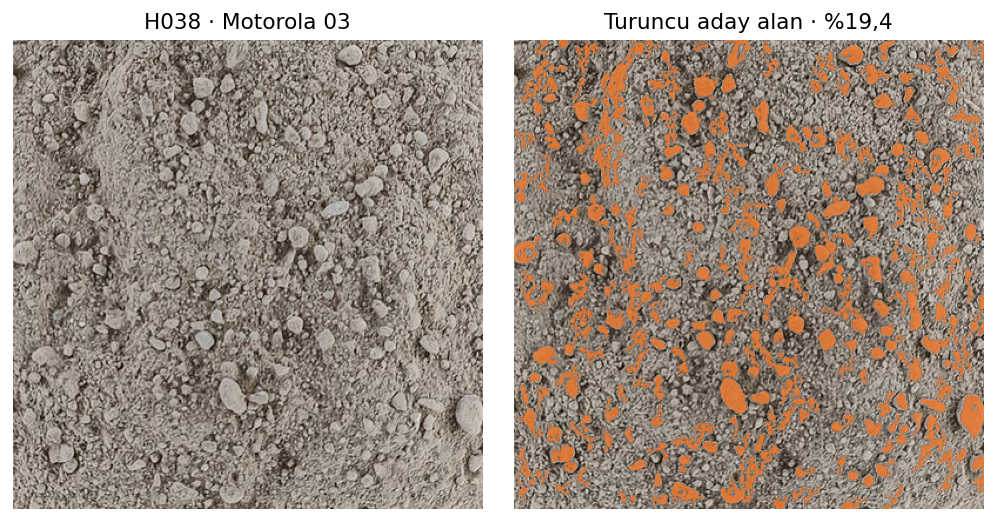

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(7.7, 3.9), layout="constrained")
left.imshow(example)
left.set_title("H038 · Motorola 03")
right.imshow(example)
overlay = np.zeros((*example_mask.shape, 4))
overlay[example_mask] = [0.94, 0.39, 0.04, 0.68]
right.imshow(overlay)
pct = f"{100 * example_mask.mean():.1f}".replace(".", ",")
right.set_title(f"Turuncu aday alan · %{pct}")
for ax in (left, right):
    ax.set_axis_off()
plt.show()